#### This notebook plots a chosen random graph with clustering analysis

In [87]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [88]:
import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt
import networkx as nx

import cnetwork

In [3]:
# Set default properties--these are what each magma chamber takes as default if
# properties are not individually specified for each chamber.

def comp_series(t_b=1e12, t_d=5e12, t_final=1e12, mass_in_rate=1.0,
                  R=500, Nr=100, R_outer_ratio=100, N_t=10000,
                  t_d_far_factor=1.0, t_d_mode="shell",
                  solve_full_matrix=False):

  R = 500

  crust_props = cnetwork.default_props(
    t_b_default = t_b,#1e9, #1e12,           # Maxwell / relaxation time (in isotropic strain) (Pa)
    t_d_default = t_d,         # Maxwell / relaxation time (in deviatoric strain) (Pa)
    K_crust_default = 10e9,     # Bulk modulus of crust (Pa)
    G_crust_default = 10e9,     # Shear modulus of crust (Pa)
    K_f_default = 1e9,         # Bulk modulus of fluid / melt (Pa)
    r_hydr_default = 5,        # Hydraulic radius of channels / dikes (m)
    mu_default = 1e6,           # Melt viscosity in crust, constant (Pa s)
  )

  other_props = dict(
    R_min = R,                # Minimum radius of magma chamber for random generation (m)
    R_max = R,                # Maximum radius of magma chamber for random generation (m)
    N_chamber = 1,             # Number of chambers to generate
    x_scale = 40000,             # Length scale of horizontal (x) direction (m)
    z_scale = 40000,             # Length scale of horizontal (x) direction (m)
    mass_in_rate = mass_in_rate,         # Input mass rate at bottom node (kg / s)
    p_erupt = 5e6,              # Overpressure required for eruption at top node (Pa)
    dpdx_crit = 5e3,            # Minimum pressure gradient for opening dike (Pa / m)
    dpdx_threshold_scale = 0.0, # Numerical smoothing parameter for dpdx_crit (Pa / m)
    # Eruption parameters (the erupting conduit is treated differently from dikes between chambers)
    mu_erupt = 1e5,             # Melt viscosity in erupting conduit (Pa s)
    r_conduit_erupt = 2500,       # Conduit radius for erupting conduit (m)
    # r_conduit_erupt = 25,       # Conduit radius for erupting conduit (m)
    rhoref = 2500,              # Reference density of fluid / melt (Pa)
  )

  numerics = cnetwork.default_numerics()
  numerics["Nr"] = Nr #20
  numerics["R_outer_ratio"] = R_outer_ratio # 100 # 20

  V = (4/3)*np.pi*R**3

  # Generate list of MagmaChamber nodes, which store the volume, mass, energy in chamber
  list_nodes = [cnetwork.MagmaChamber(x=0.0, y=0.0, z=0.0,
    p_setting=None, vref=1.0/other_props["rhoref"],
    T_setting=1000+273.15, V_setting=V)]
  # list_nodes[0].t_d = 1e10

  # Set up main system for timestepping later
  global_sys = cnetwork.GlobalSystemThreshold(list_nodes, **crust_props,
    **numerics, dpdx_crit=other_props["dpdx_crit"],
    dpdx_threshold_scale=other_props["dpdx_threshold_scale"],
    t_d_far=t_d*t_d_far_factor,
    t_d_mode=t_d_mode,
    max_edge_dist=np.inf)

  f_erupt = global_sys.create_eruptible_layer(
    z_min=-1.0,
    z_max=1.0,
    p_erupt_min=other_props["p_erupt"],
    p_erupt_max=other_props["p_erupt"],
    mu_erupt=other_props["mu_erupt"],
    r_conduit=other_props["r_conduit_erupt"])
  # f_inj = global_sys.create_mass_injection_layer(
  #   fn_z=lambda t, q, z: 1.0 * np.asarray(t < 1e12).astype(float) ,
  #   mdot_inj = 0.0*other_props["mass_in_rate"],
  #   z_max=1.0,)
  f_inj = global_sys.create_mass_injection_layer(
    fn_z=None,
    mdot_inj = 1.0*other_props["mass_in_rate"],
    z_max=1.0,)

  # Time-dependent simulation
  t_vec = np.linspace(0, t_final, N_t)
  q_out, m_erupted_out = global_sys.simulation(
    global_sys.q0, t_vec, f_inj, f_erupt,
    solve_full_matrix=solve_full_matrix)
  m_hist, p, u = global_sys.compute_m_p_u(q_out)

  return (t_vec, m_hist, p, u, q_out, m_erupted_out, global_sys, 
    (f_inj, f_erupt, list_nodes, crust_props, other_props, numerics))

In [4]:
t_vec, m_hist, p, u, q_out, m_erupted_out, global_sys, misc, = comp_series(
  t_b=1e12, t_d=1e12, mass_in_rate=1.0,
  R=500, Nr=200, R_outer_ratio=20)

In [4]:
t_vec, m_hist, p, u, q_out, m_erupted_out, global_sys, misc, = comp_series(
  t_b=1e12, t_d=1e12, mass_in_rate=1.0,
  R=500, Nr=200, R_outer_ratio=20, t_d_mode="default")

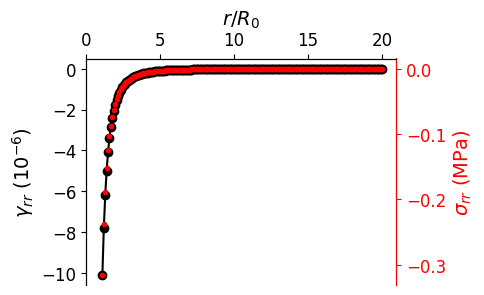

In [6]:
# q_out[]
r_normalized = global_sys.nodes[0].r_mesh / global_sys.nodes[0].R0
# Plot outer solution
t_index = 1000
# Get radial viscous strain gamma_rr
gamma_kk = q_out[t_index,global_sys.data_slice["gamma_kk"]][1:]
gamma_drr = q_out[t_index,global_sys.data_slice["gamma_drr"]][1:]
gamma_rr = gamma_drr + gamma_kk/3
# Get radial stress sigma_rr
sigma_rr = global_sys.sigma_rr(q_out[t_index,:]).squeeze()[1:]

fig, ax = plt.subplots(figsize=(4,3), dpi=100)

ax.plot(r_normalized[1:], gamma_rr * 1e6, 'ko-')
ax.set_xlabel(r"$r / R_0$",
  fontsize=14)
ax.set_ylabel(r"$\gamma_{rr}$ ($10^{-6}$)",
  fontsize=14,
  color="black")
ax.xaxis.tick_top()
ax.xaxis.set_label_position('top')

ax2 = ax.twinx()
stress_plot_handle, = ax2.plot(r_normalized[1:], sigma_rr / 1e6, 'r.')

ax2.set_ylabel(r"$\sigma_{rr}$ (MPa)",
  fontsize=14,
  color="red")

ax2.yaxis.label.set_color(stress_plot_handle.get_color())
ax2.spines["right"].set_edgecolor(stress_plot_handle.get_color())
ax2.tick_params(axis='y', colors=stress_plot_handle.get_color())
ax2.set_xlim(left=0)

ax.tick_params(labelsize=12)
ax2.tick_params(labelsize=12)

for spine in ['bottom']:
  ax.spines[spine].set_visible(False)
  ax2.spines[spine].set_visible(False)

In [5]:
def op_D(h, Nr):
    ''' Central first-derivative operator '''
    upper = 0.5/h*np.ones(Nr-1)
    upper[0] *= 2.0
    lower = -0.5/h*np.ones(Nr-1)
    lower[-1] *= 2.0
    diag = np.zeros(Nr)
    diag[0] = -1.0/h
    diag[-1] = 1.0/h
    D = scipy.sparse.diags([upper, diag, lower], [1, 0, -1])
    return D

def op_D2( h, Nr):
    ''' Central second-derivative operator. Nothing is done at the boundary. '''
    # Define left-biased derivative operator for u
    DL = scipy.sparse.lil_matrix(
        scipy.sparse.diags([1.0/h*np.ones(Nr), -1.0/h*np.ones(Nr-1)], [0, -1]))
    DL[0,:] = DL[1,:]
    # Define right-biased derivative operator for stress
    DR = scipy.sparse.lil_matrix(
        scipy.sparse.diags([-1.0/h*np.ones(Nr), 1.0/h*np.ones(Nr-1)], [0, 1]))
    DR[-1,:] = DR[-2,:]
    return DL @ DR

def op_E_drr(h, Nr, r_mesh):
  ''' Linear mapping from radial displacement to spherically symmetric deviatoric rr-strain'''
  # Diagonal matrix containing values of 1/r
  diag_inv_r = scipy.sparse.diags([1.0/r_mesh], [0])
  E_drr = (2.0/3.0) * (op_D(h, Nr) - diag_inv_r)
  return E_drr

def op_E_kk(h, Nr, r_mesh):
  ''' Linear mapping from radial displacement to spherically symmetric kk-strain'''
  # Diagonal matrix containing values of 1/r
  diag_inv_r = scipy.sparse.diags([1.0/r_mesh], [0])
  E_kk = op_D(h, Nr) + 2.0*diag_inv_r
  return E_kk

def op_A(h, Nr, r_mesh):
  ''' Elasticity differential operator valid in the interior nodes:
        d^2/dr^2 + 2/r * d/dr - 2/r^2
    '''
  diag_inv_r = scipy.sparse.diags([1.0/r_mesh], [0])
  A = (op_D2(h, Nr)
        + 2.0 * diag_inv_r @ op_D(h, Nr)
        - 2.0 * diag_inv_r * diag_inv_r)
  return A

In [6]:
# TEMP: Debug using single node
node = global_sys.nodes[0]
A = op_A(node.dx, node.Nr, node.r_mesh)
D = op_D(node.dx, node.Nr)
diag_inv_r = scipy.sparse.diags([1.0/node.r_mesh], [0])

block_size = 2*node.Nr + 4

Nr = node.Nr
dx = node.dx
L_u = scipy.sparse.lil_matrix((Nr, Nr + block_size))
# Construct elastic portion of static equilibrium equation
L_u[:, 0:Nr] = A
# Construct mapping of γ_drr to term in static equilibrium equation
L_u[:, Nr:2*Nr] = 2 * (node.G_crust/node.M_crust) * D \
                  + 6 * (node.G_crust/node.M_crust) * diag_inv_r
# Construct mapping of γ_kk to term in static equilibrium equation
L_u[:, 2*Nr:3*Nr] = (node.K_crust/node.M_crust) * D

''' Set traction boundary condition at r = R0
  \sigma_{rr} = -(p - p_0)
where \sigma_{rr} is the normal stress (in excess of "crustal prestress")
and p_0 is the pressure linearization point
'''
# Replace first row with boundary traction (normalized by M_crust) Dirichlet
# lift operator at r = R0 (linearized boundary treatment)
L_u[0, :] = 0.0
L_u[0, 0] += -1.0 / dx
L_u[0, 1] += 1.0 / dx
L_u[0, 0] += (2*node.K_crust - 4*node.G_crust/3) / node.M_crust/ node.R0
# Add r = R boundary dependence on γ_drr
L_u[0, Nr] = -2 * node.G_crust / node.M_crust
# Add r = R boundary dependence on γ_kk
L_u[0, 2*Nr] = -node.K_crust / node.M_crust
# Add r = R boundary dependence on boundary pressure, linearly dependent on u, m
L_u[0, 0] += - 3 * node.K_f / node.M_crust / node.R0
L_u[0, 3*Nr] += node.K_f / node.m0 / node.M_crust
# Add RHS loading due to traction boundary condition
f_u = np.zeros((Nr, 1))
f_u[0] += node.K_f / node.M_crust
# Save RHS as sparse vector
f_u = scipy.sparse.csc_matrix(f_u)

''' Set boundary condition at r = r_inf '''
# Replace last row with boundary displacement Dirichlet lift operator
L_u[Nr-1, :] = 0
L_u[Nr-1, Nr-1] = 1
# Finalize matrix format
L_u = L_u.tocsc()

In [7]:
# Assemble dependence of viscous strain evolution on displacement u (through elastic strain)
r_mesh = node.r_mesh
G = scipy.sparse.lil_matrix((block_size, Nr))
G[0:Nr, 0:Nr] = -1.0 / node.t_d * op_E_drr(dx, Nr, r_mesh)
if node.t_b != np.inf:
  G[Nr:2*Nr, 0:Nr] = -1.0 / node.t_b * op_E_kk(dx, Nr, r_mesh)
# Compute matrix L
node.L = scipy.sparse.lil_matrix((block_size, block_size))
node.L[np.arange(0,Nr), np.arange(0,Nr)] = (1 / node.t_d)
if node.t_b != np.inf:
  node.L[np.arange(Nr,2*Nr), np.arange(Nr,2*Nr)] = (1 / node.t_b)
# Add dependence on u through Schur complement term
node.L += G @ node.H

''' Assemble local RHS vector for a single chamber
  This is f - G @ K,
where f contains any external source terms for the time-dependent variables.
'''
# Assemble right hand side for local problem
node.f = scipy.sparse.lil_matrix((block_size, 1))
# Put dependence on spherical boundary condition
node.f -= G @ node.k

# Save reference to system matrix
# node.L_u = L_u

In [10]:
if False:
  dt = t_vec[1] - t_vec[0]

  # plt.contourf()
  L, f = global_sys.assemble_global_Lf(global_sys.q0)
  plt.contourf(L.todense())
  LHS_BE = scipy.sparse.eye(global_sys.num_dof) + dt * (L + 0)
  plt.contourf(LHS_BE.todense())
  LHS_BE.todense()[[1,3],[1,3]]

In [8]:
def plot_u_r(q, global_sys):
  node = global_sys.nodes[0]
  _uvec = (node.H @ q[:global_sys.block_size] + node.k).squeeze()
  plt.loglog(node.r_mesh, _uvec, 'b.-')
  plt.loglog(node.r_mesh, _uvec[0] * (node.r_mesh/node.r_mesh[0])**-2, 'k--')


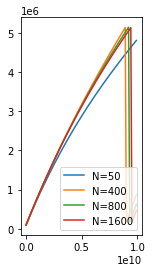

In [9]:

# plt.plot(m_hist)
# plt.plot(p)
# i = 20000
# plt.plot(q_out[i,0*numerics["Nr"]:1*numerics["Nr"]])
# plt.plot(q_out[i,1*numerics["Nr"]:2*numerics["Nr"]])
# plt.plot(t_vec, u)

i_final = 100
plt.figure(figsize=(10,4))
plt.subplot(1,4,1)
t_vec, m_hist, p, u, q_out, m_erupted_out, global_sys, misc, = comp_series(
  t_b=1e10, t_d=1e9, mass_in_rate=1.0,
  R=500, Nr=50, R_outer_ratio=25)
plt.plot(t_vec[:i_final], p[:i_final], label="N=50")
t_vec, m_hist, p, u, q_out, m_erupted_out, global_sys, misc, = comp_series(
  t_b=1e10, t_d=1e9, mass_in_rate=1.0,
  R=500, Nr=400, R_outer_ratio=25)
plt.plot(t_vec[:i_final], p[:i_final], label="N=400")
t_vec, m_hist, p, u, q_out, m_erupted_out, global_sys, misc, = comp_series(
  t_b=1e10, t_d=1e9, mass_in_rate=1.0,
  R=500, Nr=800, R_outer_ratio=25)
plt.plot(t_vec[:i_final], p[:i_final], label="N=800")
t_vec, m_hist, p, u, q_out, m_erupted_out, global_sys, misc, = comp_series(
  t_b=1e10, t_d=1e9, mass_in_rate=1.0,
  R=500, Nr=1600, R_outer_ratio=25)
# plot_u_r(q_out[100,:][:,np.newaxis], global_sys)
plt.plot(t_vec[:i_final], p[:i_final], label="N=1600")
plt.legend()


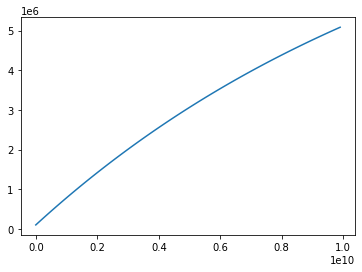

In [10]:
t_vec, m_hist, p, u, q_out, m_erupted_out, global_sys, misc, = comp_series(
  t_b=1e10, t_d=1e9,
  t_d_far_factor=1e4,
  mass_in_rate=1.0,
  t_d_mode="shell",
  R=500, Nr=1600, R_outer_ratio=25)
plt.plot(t_vec[:i_final], p[:i_final], label="N=1600")

In [11]:
_, _, _, _, q_out_equiv, _, _, _, = comp_series(
    t_b=1e10, t_d=10**8.812858963159997,
    t_d_far_factor=1,
    mass_in_rate=1.0,
    t_d_mode="shell",
    R=500, Nr=1600, R_outer_ratio=25)

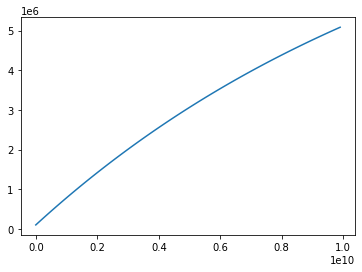

In [89]:
_, _, _, _, q_out_tb, _, _, _, = comp_series(
  t_b=1e9, t_d=1e9,
  t_d_far_factor=1e4,
  mass_in_rate=1.0,
  t_d_mode="shell",
  R=500, Nr=1600, R_outer_ratio=25)
plt.plot(t_vec[:i_final], p[:i_final], label="N=1600")

In [ ]:
_, _, _, _, q_out_tb_low, _, _, _, = comp_series(
  t_b=1e8, t_d=1e9,
  t_d_far_factor=1e4,
  mass_in_rate=1.0,
  t_d_mode="shell",
  R=500, Nr=1600, R_outer_ratio=25)
plt.plot(t_vec[:i_final], p[:i_final], label="N=1600")

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript back

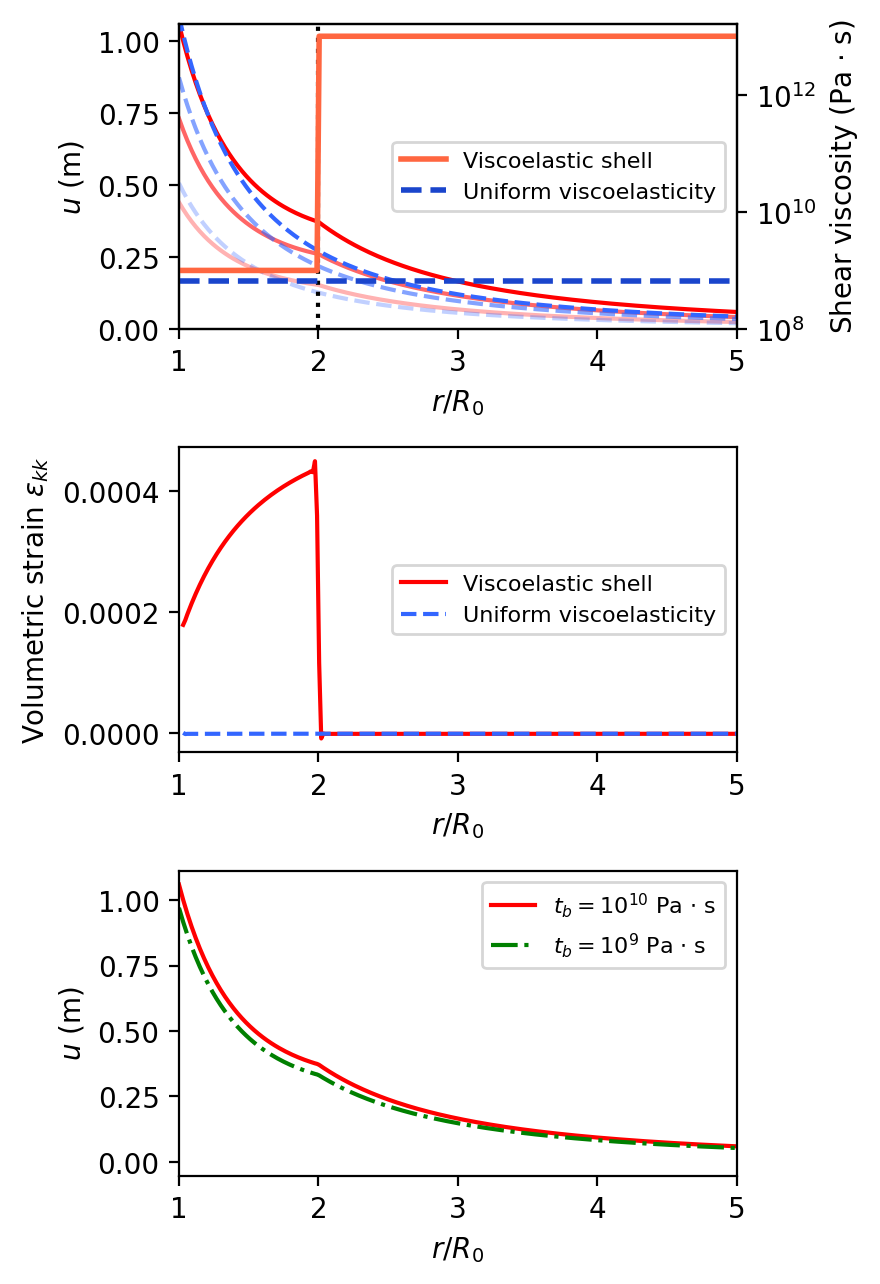

In [102]:
fig, ax = plt.subplots(3, 1, figsize=(4.5,6.5), dpi=200)

node = global_sys.nodes[0]

c_shell = [
  [1.0, 0.0, 0.0, 0.3],
  [1.0, 0.0, 0.0, 0.6],
  [1.0, 0.0, 0.0, 1.0],
]

# Time indices to select from q_out for plotting
indices = [100, 200, 300]
for i, ind in enumerate(indices):
  q = q_out[ind,:][:,np.newaxis]
  _uvec = (node.H @ q[:global_sys.block_size] + node.k).squeeze()
  ax[0].plot(node.r_mesh/node.R0, _uvec, c=c_shell[i])
  # plt.plot(node.r_mesh/node.R0, _uvec[0] * (node.r_mesh/node.r_mesh[0])**-2, 'k--')
yscale = _uvec.max()

c_uniform = [
  [0.2, 0.4, 1.0, 0.3],
  [0.2, 0.4, 1.0, 0.6],
  [0.2, 0.4, 1.0, 1.0],
]

# Time indices to select from q_out for plotting
indices = [100, 200, 300]
for i, ind in enumerate(indices):
  q = q_out_equiv[ind,:][:,np.newaxis]
  _uvec = (node.H @ q[:global_sys.block_size] + node.k).squeeze()
  ax[0].plot(node.r_mesh/node.R0, _uvec, '--', c=c_uniform[i])
  # plt.plot(node.r_mesh/node.R0, _uvec[0] * (node.r_mesh/node.r_mesh[0])**-2, 'k--')


ax[0].plot([2, 2], [0, yscale], 'k:')
ax[0].set_xlim(1,5)
ax[0].set_ylim(0, yscale)
ax[0].set_xlabel("$r / R_0$")
ax[0].set_ylabel("$u$ (m)")

secax = plt.twinx(ax[0])

visc = node.r_mesh/node.R0
t_d_r = np.full((node.Nr,), node.t_d)
t_d_r = np.where(node.r_mesh >= 2 * node.R0, node.t_d_far, t_d_r)
# secax.semilogy(node.r_mesh/node.R0, t_d_r, c=[0.3, 0.6, 0.25, 1.0], zorder=-1)
secax.semilogy(node.r_mesh/node.R0, t_d_r, c=[1.0, 0.4, 0.25, 1.0], zorder=-1, linewidth=2, label="Viscoelastic shell")
secax.semilogy(node.r_mesh/node.R0, np.full((node.Nr,), 10**8.812858963159997), '--', c=[0.1, 0.27, 0.8, 1.0],
               zorder=-1, linewidth=2, label="Uniform viscoelasticity")
secax.set_ylabel("Shear viscosity (Pa $\cdot$ s)")
secax.set_ylim(bottom=1e8)
plt.legend(fontsize=8, loc="right")

''' Bulk strain panel 2 '''

# Extract a snapshot for bulk strain evaluation
q_shell = q_out[300,:][:,np.newaxis]
u_shell = (node.H @ q_shell[:global_sys.block_size] + node.k).squeeze()
q_uniform = q_out_equiv[300,:][:,np.newaxis]
u_uniform = (node.H @ q_uniform[:global_sys.block_size] + node.k).squeeze()
# Compute bulk strain for shell and uniform viscoelasticity
r_mesh = global_sys.nodes[0].r_mesh
dr = r_mesh[1] - r_mesh[0]
Nr = r_mesh.size
strainkk_shell = (op_D(dr, Nr) @ u_shell + 2 * u_shell / r_mesh)
strainkk_uniform = (op_D(dr, Nr) @ u_uniform + 2 * u_uniform / r_mesh)

ax[1].plot(r_mesh[2:]/node.R0, strainkk_shell[2:], color=c_shell[-1],
           label="Viscoelastic shell")
ax[1].plot(r_mesh[2:]/node.R0, strainkk_uniform[2:], '--', color=c_uniform[-1],
           label="Uniform viscoelasticity")
ax[1].set_xlim(1, 5)
ax[1].set_xlabel("$r / R_0$")
ax[1].set_ylabel("Volumetric strain $\epsilon_{kk}$")
ax[1].legend(fontsize=8, loc="right")

''' Different bulk viscosities panel 3'''

ax[2].plot
q_shell = q_out[300,:][:,np.newaxis]
u_shell = (node.H @ q_shell[:global_sys.block_size] + node.k).squeeze()
q_shell_t_b = q_out_tb[300,:][:,np.newaxis]
u_shell_t_b = (node.H @ q_shell_t_b[:global_sys.block_size] + node.k).squeeze()

ax[2].plot(r_mesh/node.R0, u_shell, color=c_shell[-1],
           label="$t_b = 10^{10}$ Pa $\cdot$ s")
ax[2].plot(r_mesh/node.R0, u_shell_t_b, '-.', color="green",
           label="$t_b = 10^9$ Pa $\cdot$ s")
ax[2].set_xlim(1,5)
ax[2].legend(fontsize=8, )
ax[2].set_xlabel("$r / R_0$")
ax[2].set_ylabel("$u$ (m)")

plt.tight_layout()
plt.savefig("Single_chamber_legendtriple.png")
plt.savefig("Single_chamber_legendtriple.eps")
plt.savefig("Single_chamber_legendtriple.svg")

In [16]:
# def rootfn(t_d_exp):
#   t_vec, m_hist, p, u, q_out, m_erupted_out, global_sys, misc, = comp_series(
#     t_b=1e10, t_d=10**t_d_exp,
#     t_d_far_factor=1,
#     mass_in_rate=1.0,
#     t_d_mode="shell",
#     R=500, Nr=1600, R_outer_ratio=25)
#   print(u[300,0])
#   return u[300,0] / 2.2608522502082007 - 1.0

# out = scipy.optimize.brenth(rootfn, 8, 9)

# # 10**8.812858963159997
# t_d_equiv = 10**8.812858963159997


Text(0, 0.5, 'Viscosity (Pa s)')

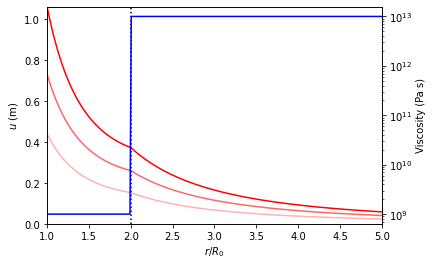

In [17]:
node = global_sys.nodes[0]

c = [
  [1.0, 0.0, 0.0, 0.3],
  [1.0, 0.0, 0.0, 0.6],
  [1.0, 0.0, 0.0, 1.0],
]

# Time indices to select from q_out for plotting
indices = [100, 200, 300]
for i, ind in enumerate(indices):
  q = q_out[ind,:][:,np.newaxis]
  _uvec = (node.H @ q[:global_sys.block_size] + node.k).squeeze()
  plt.plot(node.r_mesh/node.R0, _uvec, c=c[i])
  # plt.plot(node.r_mesh/node.R0, _uvec[0] * (node.r_mesh/node.r_mesh[0])**-2, 'k--')

yscale = _uvec.max()

plt.plot([2, 2], [0, yscale], 'k:')
plt.xlim(1,5)
plt.ylim(0, yscale)
plt.xlabel("$r / R_0$")
plt.ylabel("$u$ (m)")

ax = plt.gca()

secax = plt.twinx(ax)

visc = node.r_mesh/node.R0
t_d_r = np.full((node.Nr,), node.t_d)
t_d_r = np.where(node.r_mesh >= 2 * node.R0, node.t_d_far, t_d_r)
secax.semilogy(node.r_mesh/node.R0, t_d_r, 'b', zorder=-1)
secax.set_ylabel("Viscosity (Pa s)")

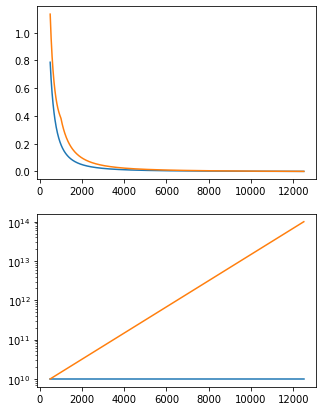

In [18]:
t_vec, m_hist, p, u, q_out, m_erupted_out, global_sys0, misc, = comp_series(
  t_b=1e10, t_d=1e10, mass_in_rate=1.0,
  R=500, Nr=800, R_outer_ratio=25,
  t_d_far_factor=1.0
  )
plt.figure(figsize=(5,7,))
plt.subplot(2,1,1)
q = q_out[-1,:][:,np.newaxis]
node = global_sys0.nodes[0]
_uvec = (node.H @ q[:global_sys0.block_size] + node.k).squeeze()
plt.plot(node.r_mesh, _uvec);

t_vec, m_hist, p, u, q_out, m_erupted_out, global_sys, misc, = comp_series(
  t_b=1e10, t_d=1e10, mass_in_rate=1.0,
  R=500, Nr=800, R_outer_ratio=25,
  t_d_far_factor=10000
  )

q = q_out[-1,:][:,np.newaxis]
node = global_sys.nodes[0]
_uvec = (node.H @ q[:global_sys.block_size] + node.k).squeeze()
plt.plot(node.r_mesh, _uvec);

plt.subplot(2,1,2)
plt.semilogy(global_sys0.nodes[0].r_mesh, np.geomspace(global_sys0.nodes[0].t_d, global_sys0.nodes[0].t_d_far, len(node.r_mesh)))
plt.semilogy(global_sys0.nodes[0].r_mesh, np.geomspace(global_sys.nodes[0].t_d, global_sys.nodes[0].t_d_far, len(node.r_mesh)))

Text(0.5, 1.0, 't_b = 1e8, t_d = 1e9, N=100')

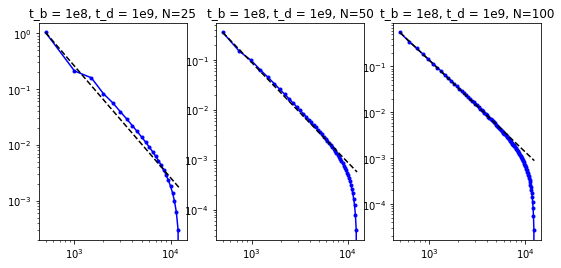

In [19]:
i_final = 100
plt.figure(figsize=(9,4))
plt.subplot(1,3,1)
t_vec, m_hist, p, u, q_out, m_erupted_out, global_sys, misc, = comp_series(
  t_b=1e8, t_d=1e9, mass_in_rate=1.0,
  R=500, Nr=25, R_outer_ratio=25)
plot_u_r(q_out[100,:][:,np.newaxis], global_sys)
# plt.plot(t_vec[:i_final], p[:i_final])
plt.title("t_b = 1e8, t_d = 1e9, N=25")
plt.subplot(1,3,2)
t_vec, m_hist, p, u, q_out, m_erupted_out, global_sys, misc, = comp_series(
  t_b=1e8, t_d=1e9, mass_in_rate=10.0,
  R=500, Nr=50, R_outer_ratio=25)
plot_u_r(q_out[100,:][:,np.newaxis], global_sys)
# plt.plot(t_vec[:i_final], p[:i_final])
plt.title("t_b = 1e8, t_d = 1e9, N=50")
plt.subplot(1,3,3)
t_vec, m_hist, p, u, q_out, m_erupted_out, global_sys, misc, = comp_series(
  t_b=1e8, t_d=1e9, mass_in_rate=100.0,
  R=500, Nr=100, R_outer_ratio=25)
plot_u_r(q_out[100,:][:,np.newaxis], global_sys)
plt.title("t_b = 1e8, t_d = 1e9, N=100")

Text(0.5, 1.0, 't_b = 1e8, t_d = 1e9, N=100')

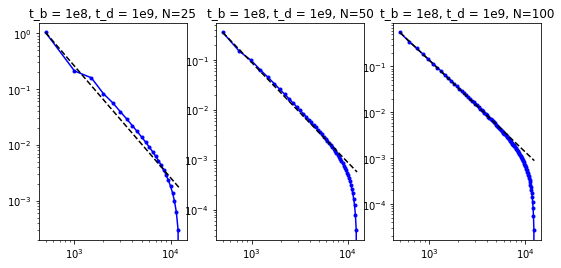

In [20]:
i_final = 100
plt.figure(figsize=(9,4))
plt.subplot(1,3,1)
t_vec, m_hist, p, u, q_out, m_erupted_out, global_sys, misc, = comp_series(
  t_b=1e8, t_d=1e9, mass_in_rate=1.0,
  R=500, Nr=25, R_outer_ratio=25)
plot_u_r(q_out[100,:][:,np.newaxis], global_sys)
# plt.plot(t_vec[:i_final], p[:i_final])
plt.title("t_b = 1e8, t_d = 1e9, N=25")
plt.subplot(1,3,2)
t_vec, m_hist, p, u, q_out, m_erupted_out, global_sys, misc, = comp_series(
  t_b=1e8, t_d=1e9, mass_in_rate=10.0,
  R=500, Nr=50, R_outer_ratio=25)
plot_u_r(q_out[100,:][:,np.newaxis], global_sys)
# plt.plot(t_vec[:i_final], p[:i_final])
plt.title("t_b = 1e8, t_d = 1e9, N=50")
plt.subplot(1,3,3)
t_vec, m_hist, p, u, q_out, m_erupted_out, global_sys, misc, = comp_series(
  t_b=1e8, t_d=1e9, mass_in_rate=100.0,
  R=500, Nr=100, R_outer_ratio=25)
plot_u_r(q_out[100,:][:,np.newaxis], global_sys)
plt.title("t_b = 1e8, t_d = 1e9, N=100")

KeyboardInterrupt: 

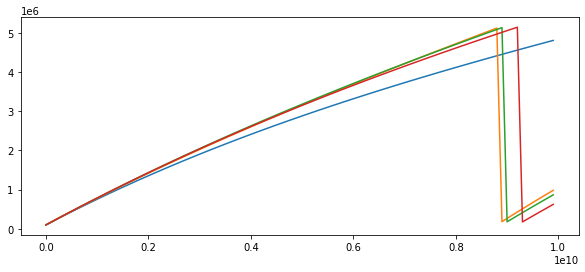

In [21]:
# plt.plot(m_hist)
# plt.plot(p)
# i = 20000
# plt.plot(q_out[i,0*numerics["Nr"]:1*numerics["Nr"]])
# plt.plot(q_out[i,1*numerics["Nr"]:2*numerics["Nr"]])
# plt.plot(t_vec, u)

i_final = 100
plt.figure(figsize=(10,4))
t_vec, m_hist, p, u, q_out, m_erupted_out, global_sys, misc, = comp_series(
  t_b=1e10, t_d=1e9, mass_in_rate=1.0,
  t_d_mode="default",
  R=500, Nr=50, R_outer_ratio=25)
plt.plot(t_vec[:i_final], p[:i_final], label="N=50")
t_vec, m_hist, p, u, q_out, m_erupted_out, global_sys, misc, = comp_series(
  t_b=1e10, t_d=1e9, mass_in_rate=1.0,
  t_d_mode="default",
  R=500, Nr=100, R_outer_ratio=25)
plt.plot(t_vec[:i_final], p[:i_final], label="N=100")
t_vec, m_hist, p, u, q_out, m_erupted_out, global_sys, misc, = comp_series(
  t_b=1e10, t_d=1e9, mass_in_rate=1.0,
  t_d_mode="default",
  R=500, Nr=400, R_outer_ratio=25)
plt.plot(t_vec[:i_final], p[:i_final], label="N=400")
t_vec, m_hist, p, u, q_out, m_erupted_out, global_sys, misc, = comp_series(
  t_b=1e10, t_d=1e9, mass_in_rate=1.0,
  t_d_mode="default",
  R=500, Nr=800, R_outer_ratio=25)
plt.plot(t_vec[:i_final], p[:i_final], label="N=800")
t_vec, m_hist, p, u, q_out, m_erupted_out, global_sys, misc, = comp_series(
  t_b=1e10, t_d=1e9, mass_in_rate=1.0,
  t_d_mode="default",
  R=500, Nr=1600, R_outer_ratio=25)
# plot_u_r(q_out[100,:][:,np.newaxis], global_sys)
plt.plot(t_vec[:i_final], p[:i_final], label="N=1600")
plt.legend()


In [ ]:
q_out.shape
node.r_mesh.shape

(1600,)

Text(0, 0.5, 'u (m)')

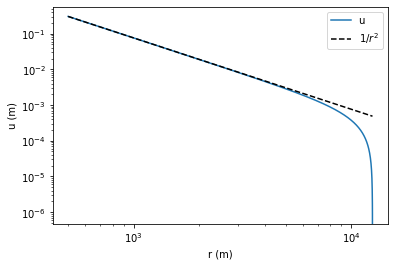

In [ ]:
q = q_out[100,:][:,np.newaxis]
node = global_sys.nodes[0]
_uvec = (node.H @ q[:global_sys.block_size] + node.k).squeeze()
plt.loglog(node.r_mesh, _uvec, label="u")
plt.loglog(node.r_mesh,
           (node.r_mesh/node.r_mesh[0])**-2*_uvec[0], 'k--',
           label="$1 / r^{2}$")
plt.legend()
plt.xlabel("r (m)")
plt.ylabel("u (m)")

### Boundary contributions

Text(0, 0.5, 'dimensionless bdry term')

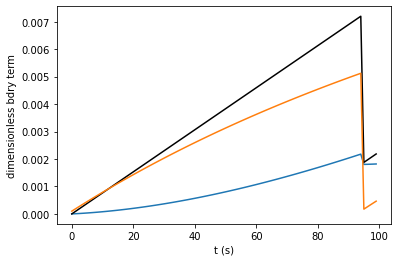

In [ ]:
_m, _p, _u = m_hist[:,0], p[:,0], u[:,0]
plt.plot(_u[:100] * 3 / node.R0, label="displacement")
plt.plot(m_hist[:100] / node.m0 - 1, 'k')
plt.plot(_p[:100] / node.K_f, label="pressure")
plt.xlabel("t (s)")
plt.ylabel("dimensionless bdry term")

### Plotting space

In [ ]:
m_hist.shape

(10000, 1)

In [ ]:
def compute_mpu(t_d=1e11, mass_in_rate=0.001, R=500):
  ''' Simulation '''
  t_vec, m_hist, p, u, q_out, m_erupted_out, global_sys, misc, = comp_series(
    t_b=1e15, t_d=t_d, t_final=0.82e11, N_t=40000, mass_in_rate=mass_in_rate,
    t_d_mode="default",
    R=R, Nr=50, R_outer_ratio=25)
  # plt.plot(t_vec[:1000], p[:1000])
  # p / u / m

  # Pick m(t), p(t), u(t) for the single chamber
  m_chamber, p_chamber, u_chamber = m_hist[:,0], p[:,0], u[:,0]
  # Track max relative mass, pressure, wall displacement
  max_mrel = (m_chamber / m_chamber[0] - 1).max()
  max_prel = (p_chamber / global_sys.nodes[0].K_f).max()
  max_urel = (u_chamber / global_sys.nodes[0].R0 * 3).max()

  return np.array([max_mrel, max_prel, max_urel]), (m_chamber, p_chamber, u_chamber), t_vec

(-4.1000000000000005, 100.0)

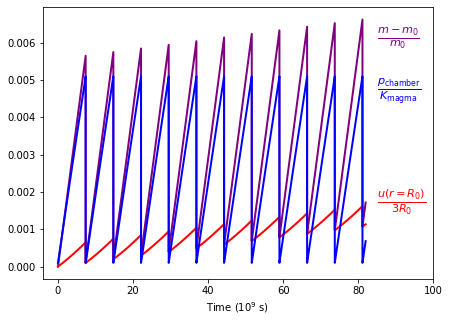

In [ ]:
mpu, (m_chamber, p_chamber, u_chamber), t_vec = compute_mpu(t_d=2e10, mass_in_rate=1, R=500)
plt.figure(figsize=(7,5))
plt.plot(t_vec / 1e9, m_chamber / m_chamber[0] - 1, 'purple', linewidth=2)
plt.plot(t_vec / 1e9, u_chamber / global_sys.nodes[0].R0 * 3, 'red', linewidth=2)
plt.plot(t_vec / 1e9, p_chamber / global_sys.nodes[0].K_f, 'blue', linewidth=2)
plt.text(85, 0.006, r"$\frac{m - m_0}{m_0}$", fontsize=16, color="purple")
plt.text(85, 0.0016, r"$\frac{u(r=R_0)}{3 R_0}$", fontsize=16, color="red")
plt.text(85, +0.0046, r"$\frac{p_\mathrm{chamber}}{K_\mathrm{magma}}$", fontsize=16, color="blue")
plt.xlabel("Time ($10^{9}$ s)")
plt.xlim(right=100)
# plt.ylabel("Boundary condition component")


(-4.1000000000000005, 100.0)

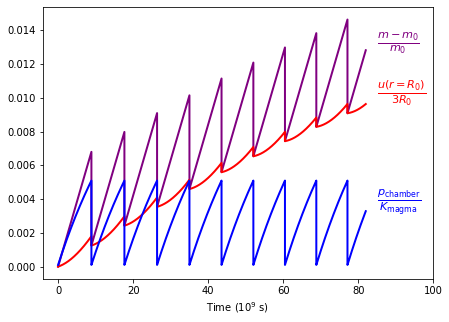

In [ ]:
mpu, (m_chamber, p_chamber, u_chamber), t_vec = compute_mpu(t_d=2e9, mass_in_rate=1, R=500)
plt.figure(figsize=(7,5))
plt.plot(t_vec / 1e9, m_chamber / m_chamber[0] - 1, 'purple', linewidth=2)
plt.plot(t_vec / 1e9, u_chamber / global_sys.nodes[0].R0 * 3, 'red', linewidth=2)
plt.plot(t_vec / 1e9, p_chamber / global_sys.nodes[0].K_f, 'blue', linewidth=2)
plt.text(85, 0.013, r"$\frac{m - m_0}{m_0}$", fontsize=16, color="purple")
plt.text(85, 0.01, r"$\frac{u(r=R_0)}{3 R_0}$", fontsize=16, color="red")
plt.text(85, +0.0036, r"$\frac{p_\mathrm{chamber}}{K_\mathrm{magma}}$", fontsize=16, color="blue")
plt.xlabel("Time ($10^{9}$ s)")
plt.xlim(right=100)
# plt.ylabel("Boundary condition component")


In [ ]:
mpu, (m_chamber, p_chamber, u_chamber), t_vec = compute_mpu(t_d=1e10, mass_in_rate=1, R=500)

vec_t_d = np.geomspace(1e9, 1e12, 24)
vec_mass_in_rate = np.geomspace(1e-2, 1e2, 18)

mg_t_d, mg_mass_in_rate = np.meshgrid(vec_t_d, vec_mass_in_rate)
mg_mpu = np.zeros((*mg_t_d.shape, 3,))

for i in range(mg_t_d.shape[0]):
  for j in range(mg_t_d.shape[1]):
    _mpu, (_m_chamber, _p_chamber, _u_chamber), _t_vec = compute_mpu(
      t_d=mg_t_d[i,j], mass_in_rate=mg_mass_in_rate[i,j], R=500)
    mg_mpu[i,j,:] = _mpu

mg_turnover_time = 1 / (mg_mass_in_rate / global_sys.nodes[0].m0)


C:\Users\Fredric\AppData\Local\Temp\ipykernel_23916\2425674288.py:53: RuntimeWarning: divide by zero encountered in true_divide
  lambda mdot: global_sys.nodes[0].m0 / mdot,


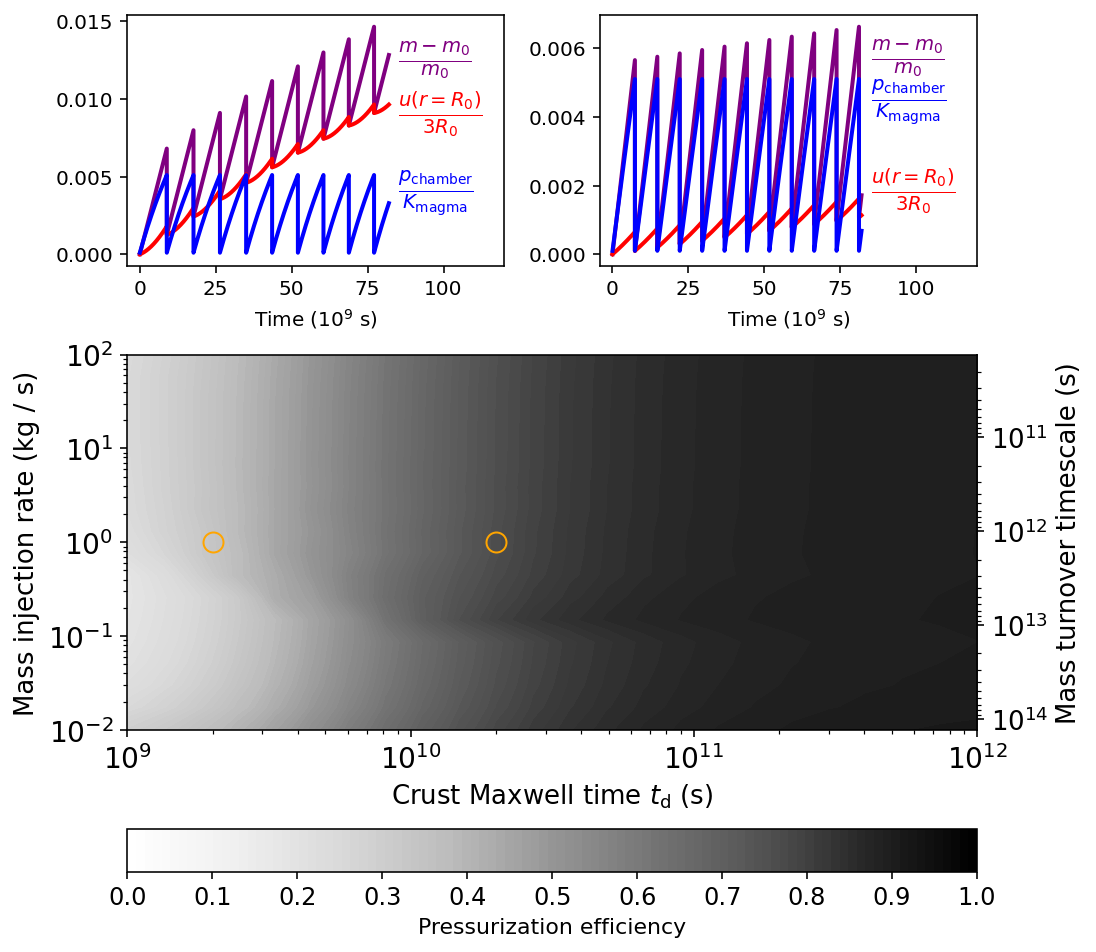

In [ ]:

fig, axes = plt.subplot_mosaic(
    [["A", "B"],
     ["C", "C"]],
    gridspec_kw = {
      "height_ratios": [1, 1.5],
    },
    constrained_layout=True,
    figsize=(7.5,6.5),
    dpi=144,
)

label_font_size=14

# Panel A: viscous crust, m(t), p(t), u(t)
mpu, (m_chamber, p_chamber, u_chamber), t_vec = compute_mpu(t_d=2e9, mass_in_rate=1, R=500)
ax = axes["A"]
ax.plot(t_vec / 1e9, m_chamber / m_chamber[0] - 1, 'purple', linewidth=2)
ax.plot(t_vec / 1e9, u_chamber / global_sys.nodes[0].R0 * 3, 'red', linewidth=2)
ax.plot(t_vec / 1e9, p_chamber / global_sys.nodes[0].K_f, 'blue', linewidth=2)
ax.text(85, 0.012, r"$\frac{m - m_0}{m_0}$", fontsize=label_font_size, color="purple")
ax.text(85, 0.0085, r"$\frac{u(r=R_0)}{3 R_0}$", fontsize=label_font_size, color="red")
ax.text(85, +0.0036, r"$\frac{p_\mathrm{chamber}}{K_\mathrm{magma}}$", fontsize=label_font_size, color="blue")
ax.set_xlabel("Time ($10^{9}$ s)")
ax.set_xlim(right=120)

# Panel B: elastic crust, m(t), p(t), u(t)
mpu, (m_chamber, p_chamber, u_chamber), t_vec = compute_mpu(t_d=2e10, mass_in_rate=1, R=500)
ax = axes["B"]
ax.plot(t_vec / 1e9, m_chamber / m_chamber[0] - 1, 'purple', linewidth=2)
ax.plot(t_vec / 1e9, u_chamber / global_sys.nodes[0].R0 * 3, 'red', linewidth=2)
ax.plot(t_vec / 1e9, p_chamber / global_sys.nodes[0].K_f, 'blue', linewidth=2)
ax.text(85, 0.0055, r"$\frac{m - m_0}{m_0}$", fontsize=label_font_size, color="purple")
ax.text(85, 0.0016, r"$\frac{u(r=R_0)}{3 R_0}$", fontsize=label_font_size, color="red")
ax.text(85, +0.0043, r"$\frac{p_\mathrm{chamber}}{K_\mathrm{magma}}$", fontsize=label_font_size, color="blue")
ax.set_xlabel("Time ($10^{9}$ s)")
ax.set_xlim(right=120)

ax = axes["C"]
_z = mg_mpu.reshape((-1, 3))
p_partition = mg_mpu[:,:,1] / (mg_mpu[:,:,1] + mg_mpu[:,:,2])
u_partition = 1 - p_partition

cf = ax.contourf(mg_t_d, mg_mass_in_rate, p_partition, levels=np.linspace(0, 1, 100),
                 cmap="Greys")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel(r"Crust Maxwell time $t_\mathrm{d}$ (s)", fontsize=13)
ax.set_ylabel("Mass injection rate (kg / s)", fontsize=13)
ax.tick_params(axis="both", labelsize=14)

sec_ax = ax.secondary_yaxis("right", functions=(
  lambda mdot: global_sys.nodes[0].m0 / mdot,
  lambda mdot: global_sys.nodes[0].m0 / mdot,
  ))
sec_ax.set_ylabel("Mass turnover timescale (s)", fontsize=13)
sec_ax.tick_params(axis="both", labelsize=13)

# cbaxes = fig.add_axes([1, 0.15, 0.03, 0.8])
cb = plt.colorbar(cf, ax=ax,
                  orientation="horizontal",
                  # cax=cbaxes
                  )
cb.set_label("Pressurization efficiency", fontsize=11)
cb.set_ticks(np.linspace(0, 1, 11))
cb.ax.tick_params(labelsize=12)
# cbaxes.tick_params(labelsize=12)

ax.plot([2e9], [1], 'o', markersize=10, mfc=[0,0,0,0], mec="orange")
ax.plot([2e10], [1], 'o', markersize=10, mfc=[0,0,0,0], mec="orange")

# plt.savefig("pressure_eff.png")
# plt.savefig("pressure_eff.eps")
# plt.savefig("pressure_eff.svg")

#### The shell, with $t_b$

In [13]:
outs0 = comp_series(
    t_final=1e11, N_t=10000, mass_in_rate=1.0,
    t_d_mode="shell", R=500, Nr=400, R_outer_ratio=10,
    t_b=1e13, t_d=1e9,
    t_d_far_factor=1e5,
    )

outs1 = comp_series(
    t_final=1e11, N_t=10000, mass_in_rate=1.0,
    t_d_mode="shell", R=500, Nr=400, R_outer_ratio=10,
    t_b=1e11, t_d=1e9,
    t_d_far_factor=1e5,
    )

outs2 = comp_series(
    t_final=1e11, N_t=10000, mass_in_rate=1.0,
    t_d_mode="shell", R=500, Nr=400, R_outer_ratio=10,
    t_b=1e9, t_d=1e9,
    t_d_far_factor=1e5,
    )

outs3 = comp_series(
    t_final=1e11, N_t=10000, mass_in_rate=1.0,
    t_d_mode="shell", R=500, Nr=400, R_outer_ratio=10,
    t_b=1e8, t_d=1e9,
    t_d_far_factor=1e5,
    )

outs4 = comp_series(
    t_final=1e11, N_t=10000, mass_in_rate=1.0,
    t_d_mode="shell", R=500, Nr=400, R_outer_ratio=10,
    t_b=1e7, t_d=1e9,
    t_d_far_factor=1e5,
    )

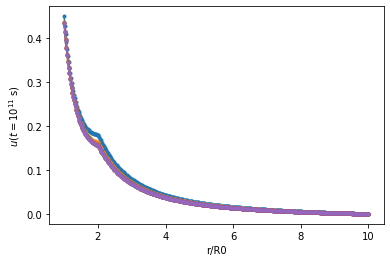

In [28]:
for out in [outs0, outs1, outs2, outs3, outs4]:
  t_vec, m_hist, p, u, q_out, m_erupted_out, global_sys, misc = out
  node = global_sys.nodes[0]
  q = q_out[-1,:][:,np.newaxis]
  _uvec = (node.H @ q[:global_sys.block_size] + node.k).squeeze()
  plt.plot(node.r_mesh/node.R0, _uvec, '.-')
  plt.xlabel("r/R0")
  plt.ylabel(r"$u(t = 10^{11}$ s$)$")

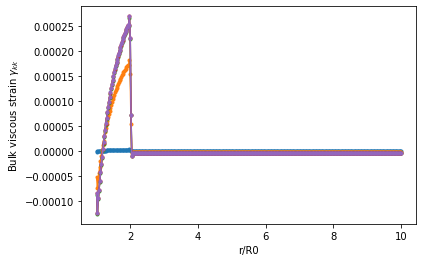

In [30]:
for out in [outs0, outs1, outs2, outs3, outs4]:
  t_vec, m_hist, p, u, q_out, m_erupted_out, global_sys, misc = out
  node = global_sys.nodes[0]
  q = q_out[-1,:][:,np.newaxis]
  _uvec = (node.H @ q[:global_sys.block_size] + node.k).squeeze()
  _gammakk = q[global_sys.data_slice["gamma_kk"]]
  # plt.loglog(node.r_mesh/node.R0, _uvec, '.-')
  plt.plot(node.r_mesh/node.R0, _gammakk, '.-')
  plt.xlabel("r/R0")
  plt.ylabel(r"Bulk viscous strain $\gamma_{kk}$")

In [16]:
outsB0 = comp_series(
    t_final=1e11, N_t=10000, mass_in_rate=1.0,
    t_d_mode="shell", R=500, Nr=400, R_outer_ratio=10,
    t_b=1e13, t_d=1e9,
    t_d_far_factor=1,
    )

outsB1 = comp_series(
    t_final=1e11, N_t=10000, mass_in_rate=1.0,
    t_d_mode="shell", R=500, Nr=400, R_outer_ratio=10,
    t_b=1e11, t_d=1e9,
    t_d_far_factor=1,
    )

outsB2 = comp_series(
    t_final=1e11, N_t=10000, mass_in_rate=1.0,
    t_d_mode="shell", R=500, Nr=400, R_outer_ratio=10,
    t_b=1e9, t_d=1e9,
    t_d_far_factor=1,
    )

outsB3 = comp_series(
    t_final=1e11, N_t=10000, mass_in_rate=1.0,
    t_d_mode="shell", R=500, Nr=400, R_outer_ratio=10,
    t_b=1e8, t_d=1e9,
    t_d_far_factor=1,
    )

outsB4 = comp_series(
    t_final=1e11, N_t=10000, mass_in_rate=1.0,
    t_d_mode="shell", R=500, Nr=400, R_outer_ratio=10,
    t_b=1e7, t_d=1e9,
    t_d_far_factor=1,
    )

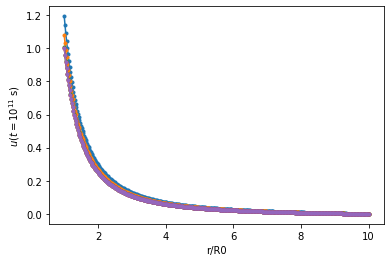

In [26]:
for out in [outsB0, outsB1, outsB2, outsB3, outsB4]:
  t_vec, m_hist, p, u, q_out, m_erupted_out, global_sys, misc = out
  node = global_sys.nodes[0]
  q = q_out[-1,:][:,np.newaxis]
  _uvec = (node.H @ q[:global_sys.block_size] + node.k).squeeze()
  plt.plot(node.r_mesh/node.R0, _uvec, '.-')
  plt.xlabel("r/R0")
  plt.ylabel(r"$u(t = 10^{11}$ s$)$")

  # _gammakk = q[global_sys.data_slice["gamma_kk"]]
  # plt.plot(node.r_mesh/node.R0, _gammakk, '.-')

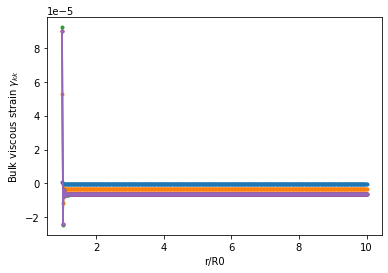

In [31]:
for out in [outsB0, outsB1, outsB2, outsB3, outsB4]:
  t_vec, m_hist, p, u, q_out, m_erupted_out, global_sys, misc = out
  node = global_sys.nodes[0]
  q = q_out[-1,:][:,np.newaxis]
  _uvec = (node.H @ q[:global_sys.block_size] + node.k).squeeze()
  _gammakk = q[global_sys.data_slice["gamma_kk"]]
  plt.plot(node.r_mesh/node.R0, _gammakk, '.-')
  plt.xlabel("r/R0")
  plt.ylabel(r"Bulk viscous strain $\gamma_{kk}$")

In [32]:
# Refinement study
outsShell0 = comp_series(
    t_final=1e11, N_t=10000, mass_in_rate=1.0,
    t_d_mode="shell", R=500, Nr=200, R_outer_ratio=10,
    t_b=1e7, t_d=1e9,
    t_d_far_factor=1e5,
    )
outsShell1 = comp_series(
    t_final=1e11, N_t=10000, mass_in_rate=1.0,
    t_d_mode="shell", R=500, Nr=400, R_outer_ratio=10,
    t_b=1e7, t_d=1e9,
    t_d_far_factor=1e5,
    )
outsShell2 = comp_series(
    t_final=1e11, N_t=10000, mass_in_rate=1.0,
    t_d_mode="shell", R=500, Nr=800, R_outer_ratio=10,
    t_b=1e7, t_d=1e9,
    t_d_far_factor=1e5,
    )
outsShell3 = comp_series(
    t_final=1e11, N_t=10000, mass_in_rate=1.0,
    t_d_mode="shell", R=500, Nr=1600, R_outer_ratio=10,
    t_b=1e7, t_d=1e9,
    t_d_far_factor=1e5,
    )

In [33]:
outsNoShell0 = comp_series(
    t_final=1e11, N_t=10000, mass_in_rate=1.0,
    t_d_mode="shell", R=500, Nr=200, R_outer_ratio=10,
    t_b=1e7, t_d=1e9,
    t_d_far_factor=1,
    )
outsNoShell1 = comp_series(
    t_final=1e11, N_t=10000, mass_in_rate=1.0,
    t_d_mode="shell", R=500, Nr=400, R_outer_ratio=10,
    t_b=1e7, t_d=1e9,
    t_d_far_factor=1,
    )
outsNoShell2 = comp_series(
    t_final=1e11, N_t=10000, mass_in_rate=1.0,
    t_d_mode="shell", R=500, Nr=800, R_outer_ratio=10,
    t_b=1e7, t_d=1e9,
    t_d_far_factor=1,
    )
outsNoShell3 = comp_series(
    t_final=1e11, N_t=10000, mass_in_rate=1.0,
    t_d_mode="shell", R=500, Nr=1600, R_outer_ratio=10,
    t_b=1e7, t_d=1e9,
    t_d_far_factor=1,
    )

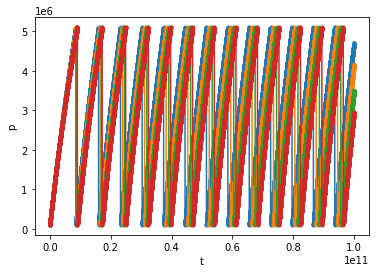

In [42]:
for out in [outsShell0, outsShell1, outsShell2, outsShell3]:
  t_vec, m_hist, p, u, q_out, m_erupted_out, global_sys, misc = out
  node = global_sys.nodes[0]
  q = q_out[-1,:][:,np.newaxis]
  _uvec = (node.H @ q[:global_sys.block_size] + node.k).squeeze()
  _gammakk = q[global_sys.data_slice["gamma_kk"]]
  # plt.plot(node.r_mesh/node.R0, _uvec, '.-')
  # plt.plot(node.r_mesh/node.R0, _gammakk, '.-')
  # plt.xlabel("r/R0")
  # plt.ylabel(r"Bulk viscous strain $\gamma_{kk}$")
  
  plt.plot(t_vec, p, '.-')
  plt.xlabel("t")
  plt.ylabel("p")


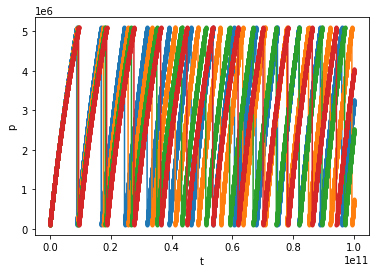

In [43]:
for out in [outsNoShell0, outsNoShell1, outsNoShell2, outsNoShell3]:
  t_vec, m_hist, p, u, q_out, m_erupted_out, global_sys, misc = out
  node = global_sys.nodes[0]
  q = q_out[-1,:][:,np.newaxis]
  _uvec = (node.H @ q[:global_sys.block_size] + node.k).squeeze()
  _gammakk = q[global_sys.data_slice["gamma_kk"]]
  # plt.plot(node.r_mesh/node.R0, _uvec, '.-')

  # plt.plot(node.r_mesh/node.R0, _gammakk, '.-')
  # plt.xlabel("r/R0")
  # plt.ylabel(r"Bulk viscous strain $\gamma_{kk}$")

  plt.plot(t_vec, p, '.-')
  plt.xlabel("t")
  plt.ylabel("p")

In [44]:
# Refinement study
outsShellT0 = comp_series(
    t_final=1e11, N_t=5000, mass_in_rate=1.0,
    t_d_mode="shell", R=500, Nr=200, R_outer_ratio=10,
    t_b=1e7, t_d=1e9,
    t_d_far_factor=1e5,
    )

outsShellT0B = comp_series(
    t_final=1e11, N_t=40000, mass_in_rate=1.0,
    t_d_mode="shell", R=500, Nr=200, R_outer_ratio=10,
    t_b=1e7, t_d=1e9,
    t_d_far_factor=1e5,
    )

outsShellT1 = comp_series(
    t_final=1e11, N_t=10000, mass_in_rate=1.0,
    t_d_mode="shell", R=500, Nr=400, R_outer_ratio=10,
    t_b=1e7, t_d=1e9,
    t_d_far_factor=1e5,
    )
outsShellT2 = comp_series(
    t_final=1e11, N_t=20000, mass_in_rate=1.0,
    t_d_mode="shell", R=500, Nr=800, R_outer_ratio=10,
    t_b=1e7, t_d=1e9,
    t_d_far_factor=1e5,
    )
outsShellT3 = comp_series(
    t_final=1e11, N_t=40000, mass_in_rate=1.0,
    t_d_mode="shell", R=500, Nr=1600, R_outer_ratio=10,
    t_b=1e7, t_d=1e9,
    t_d_far_factor=1e5,
    )

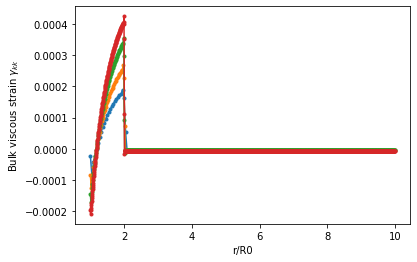

In [45]:
for out in [outsShellT0, outsShellT1, outsShellT2, outsShellT3]:
  t_vec, m_hist, p, u, q_out, m_erupted_out, global_sys, misc = out
  node = global_sys.nodes[0]
  q = q_out[-1,:][:,np.newaxis]
  _uvec = (node.H @ q[:global_sys.block_size] + node.k).squeeze()
  _gammakk = q[global_sys.data_slice["gamma_kk"]]
  # plt.plot(node.r_mesh/node.R0, _uvec, '.-')

  plt.plot(node.r_mesh/node.R0, _gammakk, '.-')
  plt.xlabel("r/R0")
  plt.ylabel(r"Bulk viscous strain $\gamma_{kk}$")

  # plt.plot(t_vec, p, '.-')
  # plt.xlabel("t")
  # plt.ylabel("p")

In [46]:
# Refinement study
outsShellX0 = comp_series(
    t_final=1e11, N_t=5000, mass_in_rate=1.0,
    t_d_mode="shell", R=500, Nr=50, R_outer_ratio=10,
    t_b=1e7, t_d=1e9,
    t_d_far_factor=1e5,
    )
outsShellX1 = comp_series(
    t_final=1e11, N_t=5000, mass_in_rate=1.0,
    t_d_mode="shell", R=500, Nr=100, R_outer_ratio=10,
    t_b=1e7, t_d=1e9,
    t_d_far_factor=1e5,
    )
outsShellX2 = comp_series(
    t_final=1e11, N_t=5000, mass_in_rate=1.0,
    t_d_mode="shell", R=500, Nr=200, R_outer_ratio=10,
    t_b=1e7, t_d=1e9,
    t_d_far_factor=1e5,
    )
outsShellX3 = comp_series(
    t_final=1e11, N_t=5000, mass_in_rate=1.0,
    t_d_mode="shell", R=500, Nr=400, R_outer_ratio=10,
    t_b=1e7, t_d=1e9,
    t_d_far_factor=1e5,
    )
outsShellX4 = comp_series(
    t_final=1e11, N_t=5000, mass_in_rate=1.0,
    t_d_mode="shell", R=500, Nr=800, R_outer_ratio=10,
    t_b=1e7, t_d=1e9,
    t_d_far_factor=1e5,
    )
outsShellX5 = comp_series(
    t_final=1e11, N_t=5000, mass_in_rate=1.0,
    t_d_mode="shell", R=500, Nr=1600, R_outer_ratio=10,
    t_b=1e7, t_d=1e9,
    t_d_far_factor=1e5,
    )
outsShellX6 = comp_series(
    t_final=1e11, N_t=5000, mass_in_rate=1.0,
    t_d_mode="shell", R=500, Nr=3200, R_outer_ratio=10,
    t_b=1e7, t_d=1e9,
    t_d_far_factor=1e5,
    )

In [ ]:
outsShellX7 = comp_series(
    t_final=1e11, N_t=5000, mass_in_rate=1.0,
    t_d_mode="shell", R=500, Nr=6400, R_outer_ratio=10,
    t_b=1e7, t_d=1e9,
    t_d_far_factor=1e5,
    )

In [51]:
outsShellX6[4].shape

(5000, 6404)

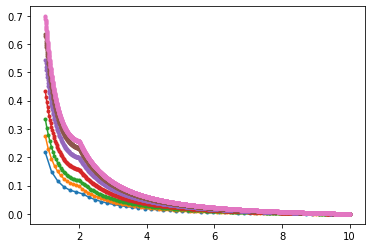

In [48]:
for out in [outsShellX0, outsShellX1, outsShellX2, outsShellX3, outsShellX4, outsShellX5, outsShellX6]:
  t_vec, m_hist, p, u, q_out, m_erupted_out, global_sys, misc = out
  node = global_sys.nodes[0]
  q = q_out[-1,:][:,np.newaxis]
  _uvec = (node.H @ q[:global_sys.block_size] + node.k).squeeze()
  _gammakk = q[global_sys.data_slice["gamma_kk"]]
  plt.plot(node.r_mesh/node.R0, _uvec, '.-')

  # plt.plot(node.r_mesh/node.R0, _gammakk, '.-')
  # plt.xlabel("r/R0")
  # plt.ylabel(r"Bulk viscous strain $\gamma_{kk}$")

  # plt.plot(t_vec, p, '.-')
  # plt.xlabel("t")
  # plt.ylabel("p")

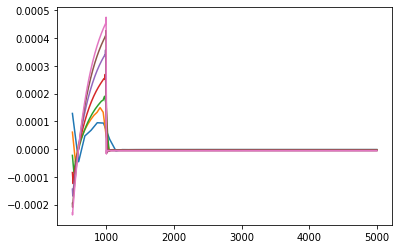

In [52]:
for out in [outsShellX0, outsShellX1, outsShellX2, outsShellX3, outsShellX4, outsShellX5, outsShellX6]:
  t_vec, m_hist, p, u, q_out, m_erupted_out, global_sys, misc = out
  node = global_sys.nodes[0]
  q = q_out[-1,:][:,np.newaxis]
  _gammakk = q[global_sys.data_slice["gamma_kk"]]
  plt.plot(node.r_mesh, _gammakk)

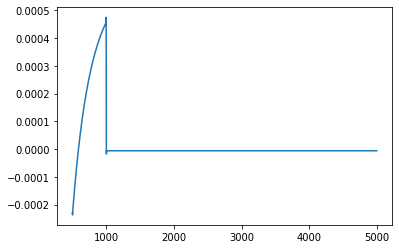

In [56]:
t_vec, m_hist, p, u, q_out, m_erupted_out, global_sys, misc = outsShellX6
node = global_sys.nodes[0]
q = q_out[-1,:][:,np.newaxis]
_gammakk = q[global_sys.data_slice["gamma_kk"]]
plt.plot(node.r_mesh, _gammakk)
import scipy.interpolate
ref_soln = scipy.interpolate.pchip(node.r_mesh, _gammakk)

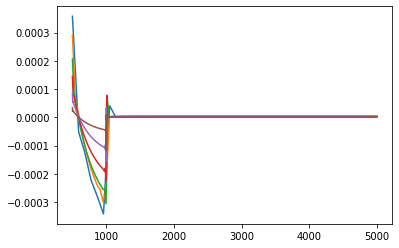

In [69]:
L2errs = []
for out in [outsShellX0, outsShellX1, outsShellX2, outsShellX3, outsShellX4, outsShellX5]:
  t_vec, m_hist, p, u, q_out, m_erupted_out, global_sys, misc = out
  node = global_sys.nodes[0]
  q = q_out[-1,:][:,np.newaxis]
  _gammakk = q[global_sys.data_slice["gamma_kk"]]
  err =  _gammakk - ref_soln(node.r_mesh)

  L2errs.append(scipy.integrate.trapezoid(err.squeeze()**2, node.r_mesh)**0.5)
  plt.plot(node.r_mesh, err)

Text(0, 0.5, '$|| \\gamma_{kk} - \\gamma_{kk,\\mathrm{ref}}||_2$')

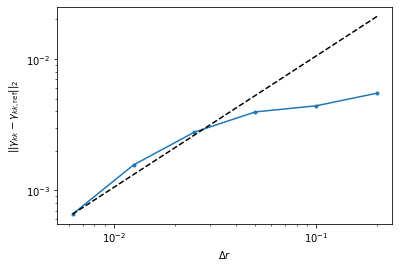

In [82]:
vec_h = 10 / (50 * 2**np.arange(6))
plt.loglog(vec_h, L2errs, '.-')
plt.loglog(vec_h, vec_h/vec_h[-1]*L2errs[-1], 'k--')
plt.xlabel("$\Delta r$")
plt.ylabel("$|| \gamma_{kk} - \gamma_{kk,\mathrm{ref}}||_2$")
